In [18]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from modules.benchmark import *
import plotly.express as px

In [33]:
physio = load_cleaned()
physio = drop_rheological(physio)
physio = add_physiochemical(physio, columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(physio)
X = drop_smiles(X)

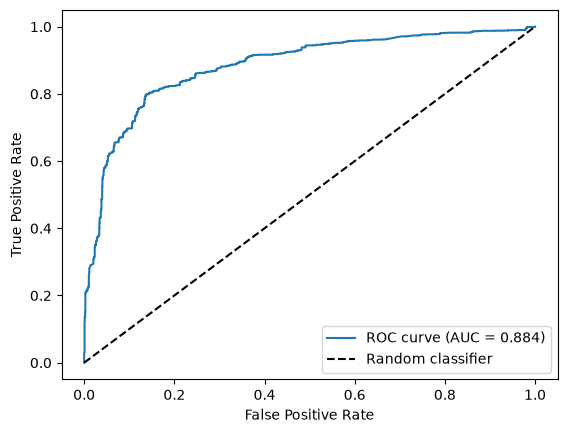

In [34]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [35]:
y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')

In [36]:
margin = np.abs(y_proba[:, 1] - y_proba[:, 0])

In [37]:
margin = pd.concat([physio, pd.DataFrame(margin, columns=['margin'])], axis=1)

In [38]:
margin.head()

,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,smiles_additive1,...,additive2_fp_247,additive2_fp_248,additive2_fp_249,additive2_fp_250,additive2_fp_251,additive2_fp_252,additive2_fp_253,additive2_fp_254,additive2_fp_255,margin
0,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.469855
1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.745326
2,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.764435
3,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.748788
4,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.787370


In [39]:
fig = px.histogram(data_frame=margin, x="margin", title="Margin Distribution")
fig.update_traces(
    xbins=dict(
        start=0.0,
        end=1.0,
        size=0.05,
    )
)
fig.show()

In [41]:
filtered = margin[margin['margin'] < 0.05].sort_values(by='margin', ascending=True)
filtered[['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2', 'margin']]

,smiles_surfactant1,smiles_surfactant2,smiles_additive1,smiles_additive2,margin
606,CCCCCCCCCCCCOCCOCCOCCOS(=O)(=O)[O-].[Na+],NaN,[Ca+2].[Cl-].[Cl-],NaN,0.000121
1869,CCCCCCC/C=C\CCCCCCCC(=O)OCCOCC(OCCO)C1OCC(OCCO...,CCCCCCCCCCCC(=O)N(C)CCO,NaN,NaN,0.000847
1259,CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-],NaN,O=C([O-])c1ccccc1O.[Na+],NaN,0.000852
1001,CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+],NaN,[I-].[Na+],NaN,0.001123
1000,CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+],NaN,[I-].[Na+],NaN,0.001123
...,...,...,...,...,...
6068,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],CCCCCCCCCCCCOC1COC2C(O)COC12,[Cl-].[Na+],NaN,0.046681
6075,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],CCCCCCCCCCCCOC1COC2C(O)COC12,[Cl-].[Na+],NaN,0.046681
7950,CCCCCCCCCCCC[N+](C)(C)C.[Br-],NaN,O=C([O-])c1ccccc1O.[Na+],NaN,0.046857
8149,CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+],CCCCCCCCCCCC[N+](C)(C)[O-],NaN,NaN,0.047195
